# AO simulation preprocessing

> !!! Batch saving not implemented !!!

In [ ]:
%matplotlib widget
import matplotlib.pyplot as plt
import h5py
import numpy as np

import pandas as pd
from matplotlib.patches import Circle
import os

import myfunctions

DELETE_RAW_FILES = False

SMALL_SIZE = 20
MEDIUM_SIZE = 22
BIGGER_SIZE = 25
GPU = True
rng_SEED = 42

train_frac = 0.7
val_frac = 0.2

outputDir = "output_prep/"
inputDir = "dataInputs/"
# inputDir= "C:/Users/dominiqu.humbert/Documents/GitHub/AO_simulations/output"

Parameters = "ao_metadata.txt"

metadata = myfunctions.read_metadata_file(inputDir + "metadata.txt")


# display(metadata)

exposureTime = metadata["exposureTime"]
startDelay = metadata["startDelay"]
singleExposureTime = 1/metadata["samplingFreq"] # [ms]
LastBatchItSize = metadata["LastBatchItSize"]
n = exposureTime + startDelay

# RWFE

1. Initialized but unused iterations are dropped.

In [ ]:
with h5py.File(inputDir+"/ao_rwfe_1.h5", 'r') as temp:
    key = list(temp.keys())
    RWFE = temp[key[0]][()][:LastBatchItSize]

ticks_spacing = 1 # [s]
print(exposureTime)
print(singleExposureTime)
ticks = np.arange(0, exposureTime + 1, ticks_spacing/singleExposureTime)

print(ticks.shape)

RWFE_mean = np.mean(RWFE[0,startDelay:LastBatchItSize])
xlims = [0, LastBatchItSize]

print("RWFE mean: ", RWFE_mean)

plt.close(0)
plt.figure(0,figsize=(10,6))
plt.semilogy(RWFE[0,:],'k', label="RWFE")
plt.hlines(RWFE_mean, startDelay, xlims[1], colors='r', linestyles='dashed', label="Mean RWFE")
plt.vlines(startDelay, 0.01,1, colors='b', label="Start Delay")
plt.ylabel("RWFE [$\\lambda$]", fontsize=MEDIUM_SIZE)
plt.xlabel("t [s]", fontsize=MEDIUM_SIZE)
plt.suptitle("RWFE vs Time", fontsize=BIGGER_SIZE)
plt.title(f"Exposure: {exposureTime*singleExposureTime} s, Start Delay: {startDelay*singleExposureTime} s, Samp.Freq: {1/singleExposureTime} Hz", fontsize=SMALL_SIZE)
plt.xlim([*xlims])
plt.xticks(ticks, [f"{singleExposureTime*t}" for t in ticks], fontsize=SMALL_SIZE)
plt.yticks(fontsize=SMALL_SIZE)
plt.grid()
plt.legend(fontsize=MEDIUM_SIZE)
plt.tight_layout()
plt.show()
plt.savefig(outputDir+"/rwfe.png", dpi=300)

del RWFE

FileNotFoundError: [Errno 2] Unable to synchronously open file (unable to open file: name = 'dataInputs/\ao_rwfe_1.h5', errno = 2, error message = 'No such file or directory', flags = 0, o_flags = 0)

# Data split

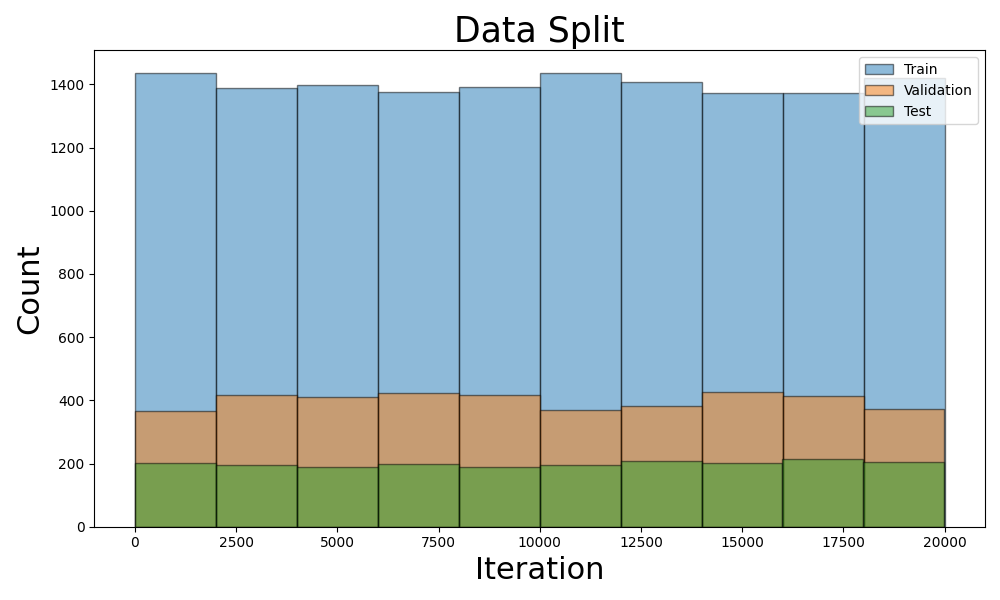

In [ ]:
rng = np.random.default_rng(rng_SEED)
n = exposureTime
indices = rng.permutation(n)  # shuffle indices

n_train = int(train_frac * n)
n_val = int(val_frac * n)

train_id = indices[:n_train]
val_id = indices[n_train:n_train + n_val]
test_id = indices[n_train + n_val:]

plt.close(0)
plt.figure(0, figsize=(10, 6))
plt.hist(train_id, bins=10, alpha=0.5, label="Train", color='#1f77b4',  edgecolor="black", linewidth=1.0)
plt.hist(val_id, bins=10, alpha=0.5, label="Validation", color='#ff7f0e', edgecolor="black", linewidth=1.0)
plt.hist(test_id, bins=10, alpha=0.5, label="Test", color='#2ca02c', edgecolor="black", linewidth=1.0)
plt.xlabel("Iteration", fontsize=MEDIUM_SIZE)
plt.ylabel("Count", fontsize=MEDIUM_SIZE)
plt.legend()
plt.title("Data Split", fontsize=BIGGER_SIZE)
plt.tight_layout()
plt.show()
plt.savefig(outputDir+"/data_split.png", dpi=300)

## DM preprocessing

1. The first StartDelay values are dropped.
2. Initialized but unused iterations are dropped.
3. The data is reshaped from 1x97 to 11x11 arrays with zero values where the (11*11-97) don't exist

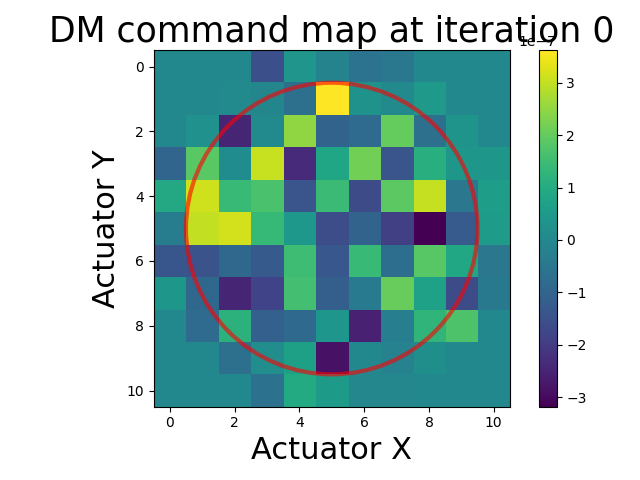

In [ ]:
act_tot = metadata["nActWSF"] + 2*metadata["edge_act"]

with h5py.File(inputDir+"/ao_DM_1.h5", 'r') as temp:
    key = list(temp.keys())
    ao_DM = temp[key[0]][()][int(startDelay):,:]
    
DM = np.zeros((int(LastBatchItSize-startDelay), int(act_tot), int(act_tot)))

for i in range(0, int(LastBatchItSize-startDelay)):
    DM[i] = myfunctions.circle_to_square(ao_DM[i], Nact1D=int(act_tot))

if os.path.exists(inputDir+"/ao_DM_"+str(1)+".h5"):
    if DELETE_RAW_FILES: os.remove(inputDir+"/ao_DM_"+str(1)+".h5")

with h5py.File(outputDir+"/ao_DM_train_"+str(1)+".h5", "w") as f:
    f.create_dataset("Training DM commands", data=DM[train_id])
with h5py.File(outputDir+"/ao_DM_val_"+str(1)+".h5", "w") as f:
    f.create_dataset("Validation DM commands", data=DM[val_id])
with h5py.File(outputDir+"/ao_DM_test_"+str(1)+".h5", "w") as f:
    f.create_dataset("Test DM commands", data=DM[test_id])

plt.close(0)
plt.figure(0)
plt.imshow(DM[0])
circle = Circle((5, 5), 4.5, color='red', fill=False, linewidth=3,alpha=0.6)
plt.gca().add_patch(circle)
plt.title("DM command map at iteration 0", fontsize=BIGGER_SIZE)
plt.colorbar()
plt.ylabel("Actuator Y", fontsize=MEDIUM_SIZE)
plt.xlabel("Actuator X", fontsize=MEDIUM_SIZE)
plt.tight_layout()

del ao_DM
del DM

## WFS

1. The first StartDelay values are dropped.
2. Initialized but unused iterations are dropped.
3. $\frac{\partial W}{dx}$ and $\frac{\partial W}{dx}$ are separated

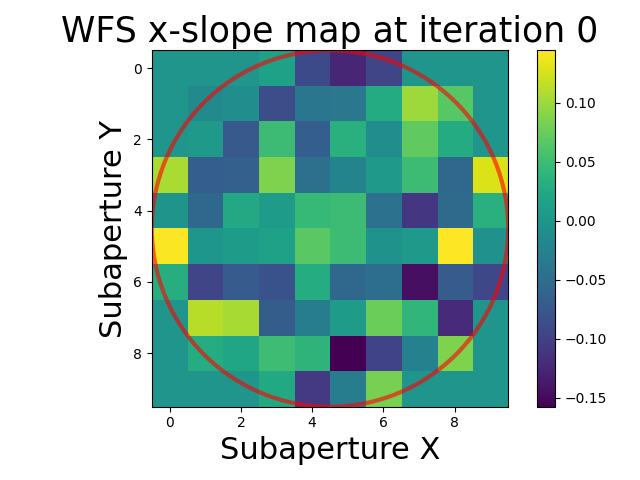

In [ ]:
with h5py.File(inputDir+"/ao_WFS_"+str(1)+".h5", 'r') as temp:
    key = list(temp.keys())
    WFSxy = temp[key[0]][()][int(startDelay):,:]

# print(WFSxy.shape[1]//2)

WFSx = np.zeros((int(LastBatchItSize-startDelay), int(act_tot)-1, int(act_tot)-1))
WFSy = np.zeros((int(LastBatchItSize-startDelay), int(act_tot)-1, int(act_tot)-1))

for i in range(0, int(LastBatchItSize-startDelay)):
    WFSx[i] = myfunctions.circle_to_square(WFSxy[i,0:WFSxy.shape[1]//2], Nact1D=int(act_tot)-1)
    WFSy[i] = myfunctions.circle_to_square(WFSxy[i,WFSxy.shape[1]//2:], Nact1D=int(act_tot)-1)

if os.path.exists(inputDir+"ao_WFS_"+str(1)+".h5"):
    if DELETE_RAW_FILES: os.remove(inputDir+"ao_WFS_"+str(1)+".h5")

with h5py.File(outputDir+"/ao_WFSx_"+"train_"+str(1)+".h5", "w") as f:
    f.create_dataset("Training WFS x", data=WFSx[train_id])
with h5py.File(outputDir+"/ao_WFSy_"+"train_"+str(1)+".h5", "w") as f:
    f.create_dataset("Training WFS y", data=WFSy[train_id])
with h5py.File(outputDir+"/ao_WFSx_"+"val_"+str(1)+".h5", "w") as f:
    f.create_dataset("Validation WFS x", data=WFSx[val_id])
with h5py.File(outputDir+"/ao_WFSy_"+"val_"+str(1)+".h5", "w") as f:
    f.create_dataset("Validation WFS y", data=WFSy[val_id])
with h5py.File(outputDir+"/ao_WFSx_"+"test_"+str(1)+".h5", "w") as f:
    f.create_dataset("Test WFS x", data=WFSx[test_id])
with h5py.File(outputDir+"/ao_WFSy_"+"test_"+str(1)+".h5", "w") as f:
    f.create_dataset("Test WFS y", data=WFSy[test_id])


plt.close(0)
plt.figure(0)
plt.imshow(WFSx[0])
plt.ylabel("Subaperture Y", fontsize=MEDIUM_SIZE)
plt.xlabel("Subaperture X", fontsize=MEDIUM_SIZE)
plt.title("WFS x-slope map at iteration 0", fontsize=BIGGER_SIZE)
circle = Circle((4.5, 4.5), 5, color='red', fill=False, linewidth=3,alpha=0.6)
plt.gca().add_patch(circle)
plt.colorbar()
plt.tight_layout()
plt.show()

del WFSxy
del WFSx
del WFSy

## Lightfield

1. The first StartDelay values are dropped.
2. Initialized but unused iterations are dropped.

In [ ]:
with h5py.File(inputDir+"/ao_lightfield_"+str(1)+".h5", 'r') as temp:
    key = list(temp.keys())
    lightfields = temp[key[0]][()][int(startDelay):int(LastBatchItSize),:]

print(lightfields.shape)

# if os.path.exists(inputDir+"/ao_lightfield_"+str(1)+".h5"):
#     if DELETE_RAW_FILES: os.remove(inputDir+"/ao_lightfield_"+str(1)+".h5")

with h5py.File(outputDir+"/ao_lightfield_"+"train_"+str(1)+".h5", "w") as f:
    f.create_dataset("Lightfield", data=lightfields[train_id])
# with h5py.File(outputDir+"/ao_lightfield_"+"val_"+str(1)+".h5", "w") as f:
#     f.create_dataset("Lightfield", data=lightfields[val_id])
# with h5py.File(outputDir+"/ao_lightfield_"+"test_"+str(1)+".h5", "w") as f:
#     f.create_dataset("Lightfield", data=lightfields[test_id])

# plt.close(0)
# plt.figure(0)
# plt.imshow(lightfields[0])
# plt.title("Lightfield image at iteration 0", fontsize=BIGGER_SIZE)
# circle = Circle((270/2, 270/2), 270/2, color='red', fill=False, linewidth=3,alpha=0.6)
# plt.gca().add_patch(circle)
# plt.colorbar()
# plt.ylabel("Pixel Y", fontsize=MEDIUM_SIZE)
# plt.xlabel("Pixel X", fontsize=MEDIUM_SIZE)
# plt.tight_layout()
# print(lightfields.shape)
# del lightfields

NameError: name 'h5py' is not defined

# Intensity map

In [ ]:
nPx_SHWFS = metadata["nPx"]
nL = metadata["nActWSF"]

with h5py.File(inputDir+"/ao_lightfield_"+str(1)+".h5", 'r') as temp:
    key = list(temp.keys())
    lightfields = temp[key[0]][()][int(startDelay):int(LastBatchItSize),:]

print(lightfields.shape)

(50000, 270, 270)


50000 270 270
27 27
(50000, 10, 10)


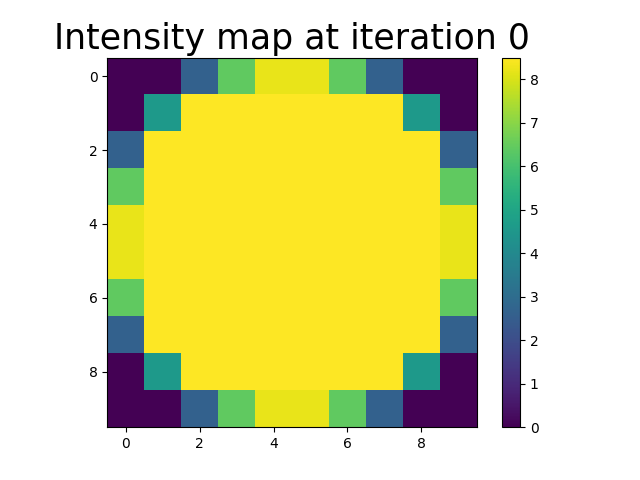

In [ ]:
n, width, height = lightfields.shape
print(n, width, height)

lenset_height = width//nL
lenset_width = height//nL
print(lenset_height, lenset_width)

intensityMap = np.zeros((n, nL, nL))
print(intensityMap.shape)

for i in range(n):
    for j in range(nL):
        for k in range(nL):
            # print(f"Processing iteration {i}, px ({j*lenset_height}->{(j+1)*lenset_height}, {k*lenset_width}->{(k+1)*lenset_width})")
            intensityMap[i, j, k] = lightfields[i, j*lenset_height:(j+1)*lenset_height, k*lenset_width:(k+1)*lenset_width].sum()

intensityMap = lightfields.reshape(n, nL, lenset_height, nL, lenset_width).sum(axis=(2, 4)) # https://stackoverflow.com/questions/25173979/aggregate-numpy-array-by-summing

if os.path.exists(inputDir+"/ao_intensity_map"+str(1)+".h5"):
    if DELETE_RAW_FILES: os.remove(inputDir+"/ao_intensity_map"+str(1)+".h5")

with h5py.File(outputDir+"/ao_intensity_map_train_"+str(1)+".h5", "w") as f:
    f.create_dataset("Training intensity map", data=intensityMap[train_id])
with h5py.File(outputDir+"/ao_intensity_map_val_"+str(1)+".h5", "w") as f:
    f.create_dataset("Validation intensity map", data=intensityMap[val_id])
with h5py.File(outputDir+"/ao_intensity_map_test_"+str(1)+".h5", "w") as f:
    f.create_dataset("Test intensity map", data=intensityMap[test_id])

plt.close(0)
plt.figure(0)
plt.imshow(intensityMap[0])
plt.title("Intensity map at iteration 0", fontsize=BIGGER_SIZE)
plt.colorbar()


# iPSF

# PSF

1. The first StartDelay values are dropped.
2. Initialized but unused iterations are dropped.

(50000, 80, 80)


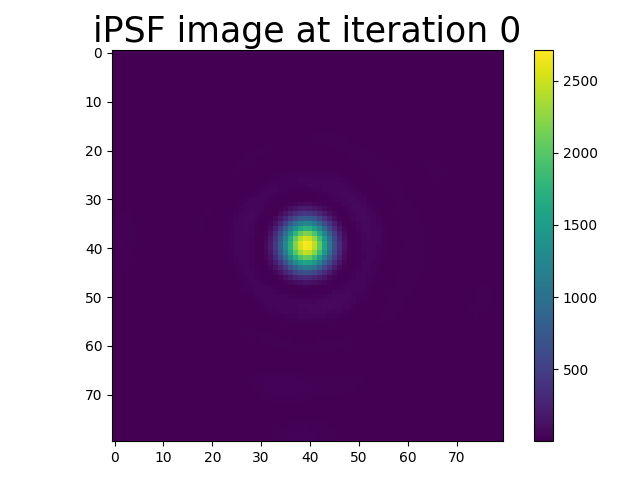

In [ ]:
with h5py.File(inputDir+"/ao_ipsf_"+str(1)+".h5", 'r') as temp:
    key = list(temp.keys())
    iPSFs = temp[key[0]][()][int(startDelay):int(LastBatchItSize),:]


if os.path.exists(inputDir+"/ao_ipsf_"+str(1)+".h5"):
    if DELETE_RAW_FILES: os.remove(inputDir+"/ao_ipsf_"+str(1)+".h5")

    with h5py.File(outputDir+"/ao_ipsf_"+"train_"+str(1)+".h5", "w") as f:
        f.create_dataset("Training iPSF", data=iPSFs[train_id])
    with h5py.File(outputDir+"/ao_ipsf_"+"val_"+str(1)+".h5", "w") as f:
        f.create_dataset("Validation iPSF", data=iPSFs[val_id])
    with h5py.File(outputDir+"/ao_ipsf_"+"test_"+str(1)+".h5", "w") as f:
        f.create_dataset("Test iPSF", data=iPSFs[test_id])
print(iPSFs.shape)
plt.close(0)
plt.figure(0)
plt.imshow(iPSFs[test_id[0]])
plt.title("iPSF image at iteration 0", fontsize=BIGGER_SIZE)
plt.colorbar()
plt.tight_layout()

del iPSFs

# Splitting data

In [ ]:
# create a .h5 file containing train_id, val_id and test_id. the file should be easy to read and parse later on.
with h5py.File(outputDir+"/data_split.h5", "w") as f:
    f.create_dataset("train_id", data=train_id)
    f.create_dataset("val_id", data=val_id)
    f.create_dataset("test_id", data=test_id)

